# Bachelor 2 Professional Project — Diabetes Classification with PyTorch
**Team members:** _Kushal, Adam, Nour_  
**Group:** _Group07_  
**Project duration:** four weeks, 16–20 hours

**Dataset (Kaggle, required):** [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)  
**Download:** open the page, download/extract the dataset and select `diabetes.csv` in the upload cell below.  
**Required final filename:** `B2_Diabetes_PyTorch_GroupXX.ipynb`.

> **Educational use only:** Historical classification data; this notebook cannot diagnose diabetes or guide medical decisions.

> **Submission:** share a viewable Google Colab link with the instructor **and** upload the downloaded `.ipynb` notebook. Include your report in Markdown cells. No separate PDF report is required.

In [14]:
!pip install torch


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [18]:

import random
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


## 0 — Setup and reproducibility
Use a CPU runtime (sufficient for this dataset). Set a reproducibility seed, show library versions and do not put Kaggle credentials in the notebook.

In [19]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Random seed:", SEED)
print("Device: CPU")

Pandas: 3.0.3
NumPy: 2.4.6
PyTorch: 2.14.1+cu130
Random seed: 42
Device: CPU


# Data Preprocessing

In [21]:
# loading the csv data into a dataframe
df = pd.read_csv('diabetes.csv')

In [33]:
columns_to_check = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in columns_to_check:
    print(f"{col}: {(df[col] == 0).sum()} zeros")

Glucose: 0 zeros
BloodPressure: 0 zeros
SkinThickness: 0 zeros
Insulin: 0 zeros
BMI: 0 zeros


In [34]:
df[columns_to_check] = df[columns_to_check].replace(0, np.nan)

print("Missing values after replacing zeros:")
print(df.isna().sum())

Missing values after replacing zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [35]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# First, separate the training set from the remaining 40%.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

# Split the remaining data equally into validation and test sets.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)


print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (460, 8)
Validation set: (154, 8)
Test set: (154, 8)


In [36]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fit the imputer on training data only.
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

# Fit the scaler on training data only.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing completed.")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Preprocessing completed.
Training: (460, 8)
Validation: (154, 8)
Test: (154, 8)


### Handling Missing Values

The dataset contains zero values in the Glucose, BloodPressure, SkinThickness, Insulin, and BMI columns. These values may represent missing or implausible measurements rather than actual measurements. Therefore, we replace these zeros with missing values (`NaN`).

We use median imputation because the median is less sensitive to extreme values than the mean. To prevent data leakage, the imputer and standard scaler are fitted only on the training set. The same fitted transformations are then applied to the validation and test sets.

Zeros in Pregnancies and Outcome are preserved because they can represent valid values.
<hr>

Build M1: The single-neuron model

In [37]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Convert features to float32 tensors.
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Convert labels to float32 tensors with shape [number_of_samples, 1].
y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)
print("Test tensors:", X_test_tensor.shape, y_test_tensor.shape)

Training tensors: torch.Size([460, 8]) torch.Size([460, 1])
Validation tensors: torch.Size([154, 8]) torch.Size([154, 1])
Test tensors: torch.Size([154, 8]) torch.Size([154, 1])


In [38]:
# Use three features from the original dataset.
demo_features = ["Glucose", "BMI", "Age"]

demo_row = df[demo_features].dropna().iloc[0]

x_demo = torch.tensor(
    demo_row.to_numpy(dtype=np.float32),
    dtype=torch.float32
)

# Create trainable weights and bias.
weights = torch.randn(3, requires_grad=True)
bias = torch.zeros(1, requires_grad=True)

# Example label for the demonstration.
target = torch.tensor([1.0])

# Forward pass.
logit = torch.sum(weights * x_demo) + bias
probability = torch.sigmoid(logit)

# Calculate loss.
loss = nn.BCEWithLogitsLoss()(logit.reshape(1), target)

# Calculate gradients.
loss.backward()

print("Input features:", x_demo)
print("Logit:", logit.item())
print("Sigmoid score:", probability.item())
print("Loss:", loss.item())
print("Weight gradients:", weights.grad)
print("Bias gradient:", bias.grad)

Input features: tensor([148.0000,  33.6000,  50.0000])
Logit: 65.88128662109375
Sigmoid score: 1.0
Loss: 2.4441101227946822e-29
Weight gradients: tensor([0., 0., 0.])
Bias gradient: tensor([0.])


In [39]:
class SingleNeuron(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(8, 1)

    def forward(self, x):
        return self.linear(x)


torch.manual_seed(42)

model_m1 = SingleNeuron()

print(model_m1)

SingleNeuron(
  (linear): Linear(in_features=8, out_features=1, bias=True)
)


In [41]:
def train_model(model, X_train, y_train, X_val, y_val,
                epochs=100, learning_rate=0.01):

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_state = None

    for epoch in range(epochs):
        # Training phase.
        model.train()
        optimizer.zero_grad()

        train_logits = model(X_train)
        train_loss = criterion(train_logits, y_train)

        train_loss.backward()
        optimizer.step()

        # Validation phase.
        model.eval()

        with torch.no_grad():
            val_logits = model(X_val)
            val_loss = criterion(val_logits, y_val)

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

        # Keep the model with the lowest validation loss.
        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }

    model.load_state_dict(best_state)

    print("Best validation loss:", round(best_val_loss, 4))

    return train_losses, val_losses


m1_train_losses, m1_val_losses = train_model(
    model_m1,
    X_train_tensor,
    y_train_tensor,
    X_val_tensor,
    y_val_tensor
)

Best validation loss: 0.4547


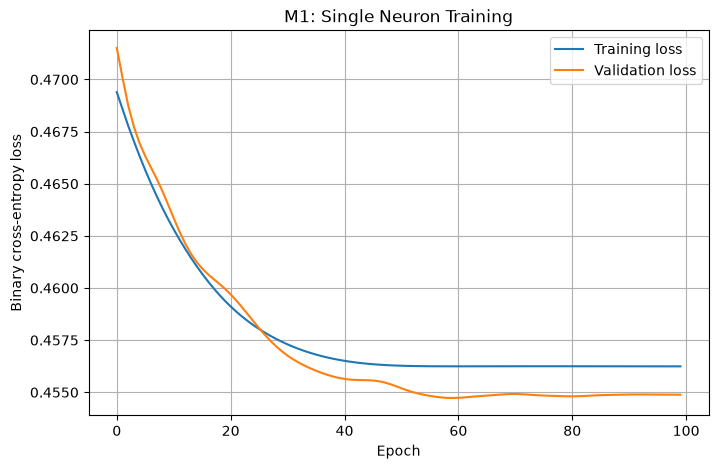

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(m1_train_losses, label="Training loss")
plt.plot(m1_val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("M1: Single Neuron Training")
plt.legend()
plt.grid(True)
plt.show()